# 03 - Feature engineering (retail churn)

Features here are **row-level and unfitted** (ratios of columns the same customer already has), so they can be computed on the full table without leakage. Anything that must be *fitted* (imputing, scaling, one-hot encoding) lives in a scikit-learn `Pipeline` and is fitted on training folds only.

| Retail signal | Built from | Feature |
|---|---|---|
| Spend rate | total spend / years as customer | `spend_per_year` |
| Purchase rate | purchases / years as customer | `purchases_per_year` |
| Basket size over a lifetime | total spend / purchases | `spend_per_purchase` |
| Dissatisfaction with products | returns / purchases | `return_rate` |
| Service friction | support contacts / years as customer | `support_contacts_per_year` |
| Typical gap between purchases | 365 x years / purchases | `purchase_gap_days` |
| **Overdue vs own rhythm** | days since last purchase / typical gap | `overdue_ratio` |
| Share of wallet (proxy) | spend per year / annual income | `spend_to_income` |

`overdue_ratio` is the main idea: 90 days of silence means something different for someone who buys weekly than for someone who buys twice a year.

Columns not in the dataset (e.g. basket-level history, channel mix, payment delays) are not fabricated.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
try:
    from src import config
except ImportError:
    from src import configs as config   # same file, saved under either name

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

T = config.TARGET
feats = pd.read_csv(config.FEATURES_CSV)
print(feats.shape, f"| overall churn rate: {feats[T].mean():.1%}")

(1000, 25) | overall churn rate: 52.6%


## Build the features

In [2]:
ENG = ["spend_per_year", "purchases_per_year", "spend_per_purchase", "return_rate",
       "support_contacts_per_year", "purchase_gap_days", "overdue_ratio", "spend_to_income"]

def add_retail_features(df):
    d = df.copy()
    yrs = d["years_as_customer"].clip(lower=1)           # avoid divide-by-zero for brand-new customers
    n = d["num_of_purchases"].replace(0, np.nan)
    inc = d["annual_income"].replace(0, np.nan)
    gap = 365 * yrs / n
    new = {
        "spend_per_year": d["total_spend"] / yrs,
        "purchases_per_year": d["num_of_purchases"] / yrs,
        "spend_per_purchase": d["total_spend"] / n,
        "return_rate": d["num_of_returns"] / n,
        "support_contacts_per_year": d["num_of_support_contacts"] / yrs,
        "purchase_gap_days": gap,
        "overdue_ratio": d["last_purchase_days_ago"] / gap,
        "spend_to_income": (d["total_spend"] / yrs) / inc,
    }
    for k, v in new.items():
        if k not in d.columns:                           # keep the CSV's version if it already has one
            d[k] = v.replace([np.inf, -np.inf], np.nan)
    return d

feats = add_retail_features(feats)
feats[ENG].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
spend_per_year,1000.0,980.31,1453.64,9.90,272.96,525.02,1016.49,9999.49
purchases_per_year,1000.0,9.97,14.86,0.06,2.56,5.12,10.00,99.00
spend_per_purchase,1000.0,271.73,793.77,1.58,54.86,100.62,198.10,9958.72
return_rate,1000.0,0.24,0.60,0.00,0.04,0.09,0.18,8.00
support_contacts_per_year,1000.0,0.37,0.57,0.00,0.07,0.20,0.43,4.00
purchase_gap_days,1000.0,191.49,523.44,3.69,36.50,71.32,142.97,5840.00
overdue_ratio,1000.0,4.97,9.07,0.00,0.74,2.09,4.69,85.27
spend_to_income,1000.0,63.39,63.88,0.76,24.10,43.97,77.33,438.88


In [3]:
print("Missing values in engineered features:")
feats[ENG].isna().sum().loc[lambda s: s > 0]

Missing values in engineered features:


Series([], dtype: int64)

## Do the engineered features separate churners?

In [4]:
def rate_by(col, q=4):
    s = feats[col]
    s = s if s.nunique() <= 10 else pd.qcut(s, q, duplicates="drop")
    out = feats.groupby(s, observed=True)[T].agg(customers="size", churn_rate="mean")
    out["churn_rate"] = (out["churn_rate"] * 100).round(1)
    return out

for c in ENG:
    print(f"--- {c}"); print(rate_by(c).to_string()); print()

--- spend_per_year
                              customers  churn_rate
spend_per_year                                     
(9.899000000000001, 272.962]        250        48.4
(272.962, 525.015]                  250        51.2
(525.015, 1016.488]                 250        56.8
(1016.488, 9999.49]                 250        54.0

--- purchases_per_year
                    customers  churn_rate
purchases_per_year                       
(0.059, 2.558]            250        54.8
(2.558, 5.12]             250        51.2
(5.12, 10.0]              254        50.8
(10.0, 99.0]              246        53.7

--- spend_per_purchase
                              customers  churn_rate
spend_per_purchase                                 
(1.5830000000000002, 54.855]        250        46.8
(54.855, 100.619]                   250        55.2
(100.619, 198.105]                  250        53.2
(198.105, 9958.72]                  250        55.2

--- return_rate
                 customers  churn_rate
r

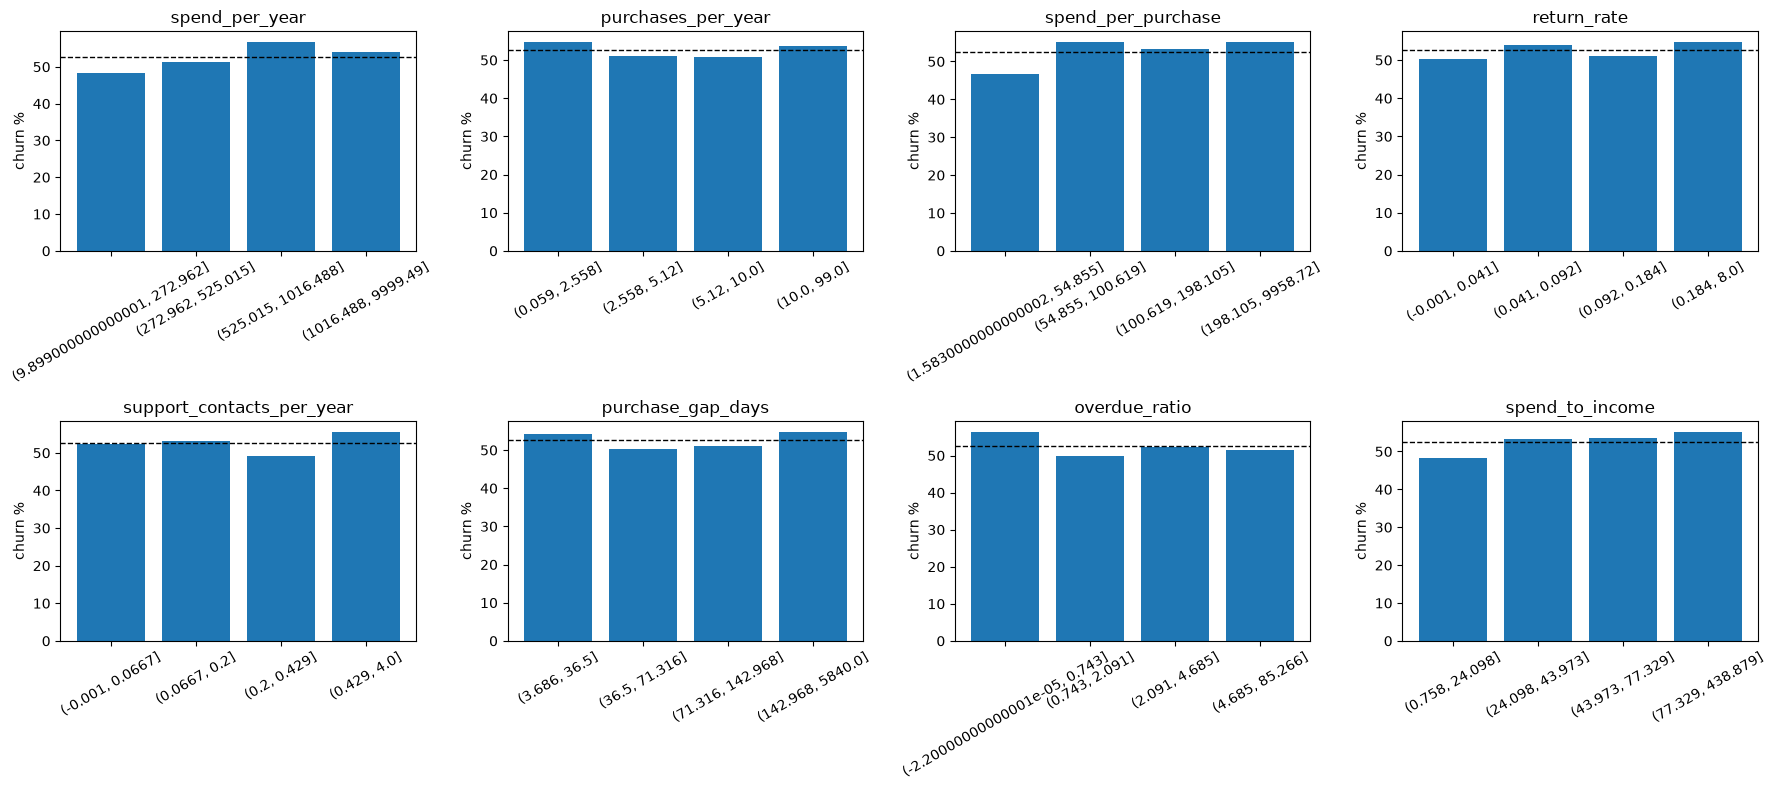

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), ENG):
    d = rate_by(c)
    ax.bar(d.index.astype(str), d["churn_rate"])
    ax.axhline(feats[T].mean() * 100, color="k", ls="--", lw=1)
    ax.set_title(c); ax.set_ylabel("churn %")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "fe_churn_by_feature.png", dpi=120)
plt.show()

## Do they carry more signal than the raw columns they come from?

In [6]:
def effect(col):
    a, b = feats.loc[feats[T] == 1, col].dropna(), feats.loc[feats[T] == 0, col].dropna()
    u, p = stats.mannwhitneyu(a, b)
    return {"feature": col, "p_value": p, "effect_size (rank-biserial r)": abs(1 - 2 * u / (len(a) * len(b)))}

raw = ["total_spend", "num_of_purchases", "num_of_returns", "num_of_support_contacts",
       "last_purchase_days_ago", "years_as_customer", "annual_income"]
cmp = pd.DataFrame([effect(c) for c in raw + ENG])
cmp["type"] = ["raw"] * len(raw) + ["engineered"] * len(ENG)
cmp.sort_values("effect_size (rank-biserial r)", ascending=False).round(4)

,feature,p_value,effect_size (rank-biserial r),type
9,spend_per_purchase,0.0975,0.0606,engineered
14,spend_to_income,0.1050,0.0593,engineered
7,spend_per_year,0.1178,0.0572,engineered
6,annual_income,0.2448,0.0426,raw
10,return_rate,0.2655,0.0407,engineered
1,num_of_purchases,0.2905,0.0387,raw
5,years_as_customer,0.3488,0.0342,raw
0,total_spend,0.3644,0.0332,raw
11,support_contacts_per_year,0.3691,0.0327,engineered
13,overdue_ratio,0.3736,0.0326,engineered


*Fill in after running (numbers, not impressions):*

1. **Overdue vs own rhythm:** churn rate in the top vs bottom `overdue_ratio` quartile, compared with the same split on raw `last_purchase_days_ago`.
2. **Return rate and support contacts per year:** do the rates separate churners better than the raw counts?
3. **Weakest engineered feature:** which one barely moves churn in any band?

## Deliberately left out of the model

Do not add recodings of columns that are already one-hot encoded (for example `is_female`, `is_email_opt_in`, or bucketed `satisfaction_score`) - duplicates split SHAP credit between two columns that mean the same thing. Bucketed versions are fine in a BI view, not as model inputs.

## Did it help? Ablation (raw columns vs raw + engineered)

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat = list(config.CATEGORICAL_FEATURES)
base_num = [c for c in config.NUMERIC_FEATURES if c not in ENG]
cv = StratifiedKFold(5, shuffle=True, random_state=42)

models = {
    "boosted trees (depth 2)": GradientBoostingClassifier(n_estimators=300, max_depth=2, learning_rate=0.05, random_state=42),
    "logistic regression": LogisticRegression(max_iter=2000),
}

def cv_auc(num_cols, model):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    pipe = Pipeline([("pre", pre), ("model", model)])
    s = cross_val_score(pipe, feats[cat + num_cols], feats[T], cv=cv, scoring="roc_auc")
    return s.mean(), s.std()

rows = []
for name, m in models.items():
    for label, cols in [("raw columns", base_num), ("raw + engineered", base_num + ENG)]:
        mean, std = cv_auc(cols, m)
        rows.append({"model": name, "features": label, "cv_roc_auc": mean, "std": std})
ablation = pd.DataFrame(rows).round(4)
ablation

KeyError: "['support_contact_rate', 'rescency_ratio', 'spend_to_income_ratio'] not in index"

*Fill in after running:* did the engineered set move CV ROC-AUC by more than its fold-to-fold std? Trees can learn ratios such as spend per year from raw columns, so a gain is more likely for the logistic regression than for boosted trees. If there is no gain, keep the features for explanations and segments, not accuracy.

## Wiring into the pipeline

- Add the engineered columns to `ENGINEERED_NUMERIC` in the config (only those you decide to keep):

```python
ENGINEERED_NUMERIC = ["spend_per_year", "purchases_per_year", "spend_per_purchase", "return_rate",
                      "support_contacts_per_year", "purchase_gap_days", "overdue_ratio", "spend_to_income"]
```

- Add a readable entry for each in `FEATURE_LABELS` (the EDA and SHAP plots use them).
- Mirror the formulas in the SQLite `customer_features` view if the pipeline reads features from SQL; `return_rate` and `overdue_ratio` need `NULLIF(num_of_purchases, 0)` to avoid divide-by-zero.